## Analysing Agents' Sales Behaviour in the month of October visavis all the before lifetime sales

This analysis finds the agents who browse products on the PWA platform but write relatively few policies, and separates agents whose business is slowing from those still producing. It covers the agents on the 'Low frewuency(browse over buy)' tab of the warehouse-verified extract dated October 31st, 2026


We are moving agents from the old agent platform to the PWA. Product-view tracking on the PWA began around Sep 30, 2026, so September 30th is the dividing line: sales before it show each agent's history, and sales since it show current activity.Comparing the two shows who has slowed down, not just who sells little.




In [18]:
 #Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path


import warnings
warnings.filterwarnings('ignore')

The first sheet holds 367 agents identified as droppers i.e., those agents that browse alot and make quotes but make relatively fewer sales on the platform. There are sales made on the PWA and the Old platform, we also want to check the interactions on both platforms

In [19]:
data = pd.read_excel('oct_data.xlsx', sheet_name= 'Droppers (no sales since Sep30)')

data.head()


,products_viewed,view_events,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date
0,18,61,0,6,Nemwel Peter,Kisii,nemwelpeter@gmail.com,254115290186,0,0,0,NaT
1,15,43,0,0,Bashir Al amin,Mombasa,bashir_1980@hotmail.com,254722571433,0,0,0,NaT
2,15,34,0,1,Justine Omari,Kiambu,justine1omar@gmail.com,254704100930,0,0,0,NaT
3,11,32,35,52,Jackson Ngigi Mburu,Kiambu,jacksonngigi1@gmail.com,254703258044,0,19,16,2026-09-14
4,10,24,111,127,ENOS LICHA,Nairobi City,enoslicha224@gmail.com,254720489337,3,45,66,2026-09-29


In [20]:
data['last_sale_date'].isna().sum()

119

In [21]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   products_viewed     367 non-null    int64         
 1   view_events         367 non-null    int64         
 2   all_sales_alltime   367 non-null    int64         
 3   quotes_alltime      367 non-null    int64         
 4   user_name           367 non-null    object        
 5   county              363 non-null    object        
 6   email               367 non-null    object        
 7   phone_number        367 non-null    int64         
 8   unpaid_policies     367 non-null    int64         
 9   pwa_sales           367 non-null    int64         
 10  old_platform_sales  367 non-null    int64         
 11  last_sale_date      248 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(8), object(3)
memory usage: 34.5+ KB


In [22]:
data.columns

Index(['products_viewed', 'view_events', 'all_sales_alltime', 'quotes_alltime',
       'user_name', 'county', 'email', 'phone_number', 'unpaid_policies',
       'pwa_sales', 'old_platform_sales', 'last_sale_date'],
      dtype='object')

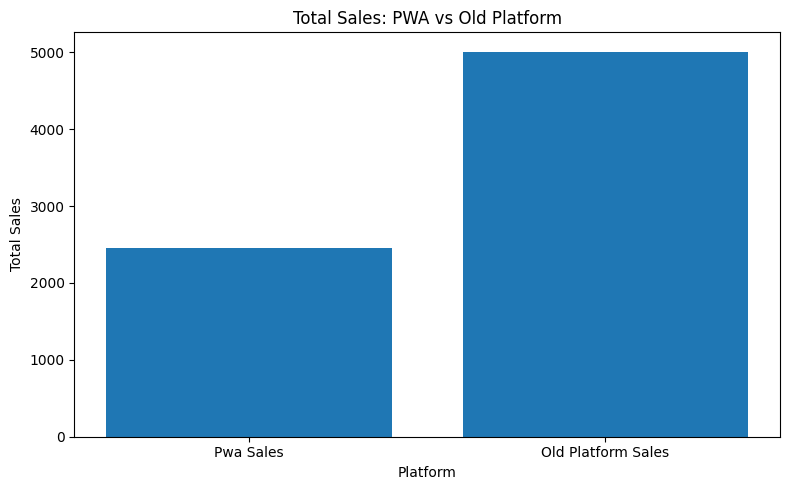

In [23]:
pwa_total = data['pwa_sales'].sum()
old_total = data['old_platform_sales'].sum()

platforms = ['Pwa Sales', 'Old Platform Sales']
sales = [pwa_total, old_total]

plt.figure(figsize=(8,5))
bars = plt.bar(platforms, sales)

plt.title('Total Sales: PWA vs Old Platform')
plt.ylabel('Total Sales')
plt.xlabel('Platform')
plt.tight_layout()
plt.show()

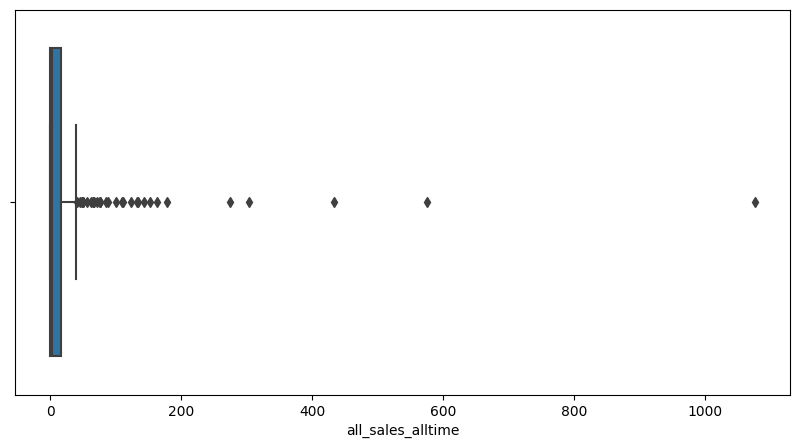

In [24]:
plt.figure(figsize=(10,5))
sns.boxplot(x=data['all_sales_alltime']);

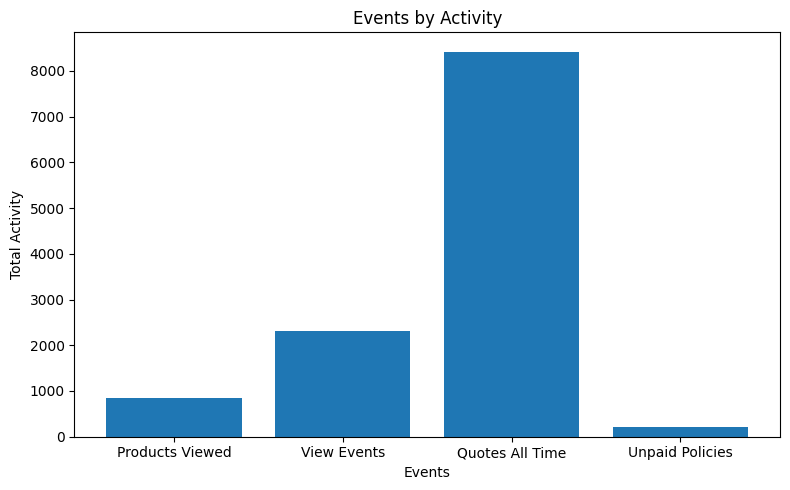

In [25]:
products_viewed_total = data['products_viewed'].sum()
view_events_total = data['view_events'].sum()
quotes_alltime_total = data['quotes_alltime'].sum()
unpaid_total = data['unpaid_policies'].sum()


events = ['Products Viewed', 'View Events', 'Quotes All Time', 'Unpaid Policies']
activity = [products_viewed_total, view_events_total, quotes_alltime_total, unpaid_total]

plt.figure(figsize=(8,5))
bars = plt.bar(events, activity)

plt.title('Events by Activity')
plt.ylabel('Total Activity')
plt.xlabel('Events')
plt.tight_layout()
plt.show()

Group agents based on how long ago they made their last sale, using the most 'recent sale date' in the dataset as the reference date

In [56]:
latest_date = data['last_sale_date'].max()   #the most recent date
print(latest_date)

#days since last sale
data['days_since_last_sale'] = (latest_date - data['last_sale_date']).dt.days

#categorise agents
data['sales_recency'] = pd.cut(
    data['days_since_last_sale'],
    bins = [-1, 30, float('inf')],
    labels = ['Recent (0- 30 days)', 'Inactive (> 30 days)']
)

#missing dates
data['sales_recency'] = data['sales_recency'].cat.add_categories('No Sales').fillna('No Sales')

2026-09-29 00:00:00


Count agents in each category

In [27]:
data['sales_recency'].value_counts()

sales_recency
Recent (0- 30 days)     129
Inactive (> 30 days)    119
No Sales                119
Name: count, dtype: int64

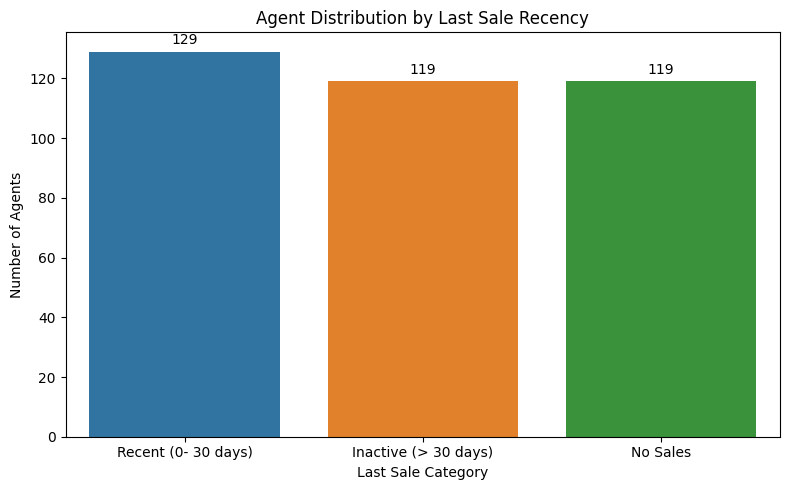

In [28]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=data,
    x ='sales_recency',
    order = [
        'Recent (0- 30 days)',
        'Inactive (> 30 days)',
        'No Sales'
    ]
)

plt.title('Agent Distribution by Last Sale Recency')
plt.xlabel('Last Sale Category')
plt.ylabel('Number of Agents')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

## MODELING

In [29]:
data2 = pd.read_excel('oct_data.xlsx', sheet_name= 'Low-freq buyers (enriched)')

data2.head()

,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date
0,43,136,2,21.5,5,6,Eastman Magembe,NaN,emagembe2019@gmail.com,254705440772,0,3,2,2026-10-30
1,35,78,2,17.5,20,29,Benson Anunda Simiyu,Nairobi City,anundabenson2002@gmail.com,254112572179,3,19,1,2026-10-19
2,17,53,1,17.0,218,237,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,254722518214,2,20,198,2026-10-02
3,12,37,1,12.0,104,102,James Muoki,Nairobi City,jmuoki88@gmail.com,254714831970,5,76,28,2026-10-15
4,11,44,1,11.0,2,11,ROSE MULI,Nairobi City,rose@fursainsurance.co.ke,254111667594,0,2,0,2026-10-01


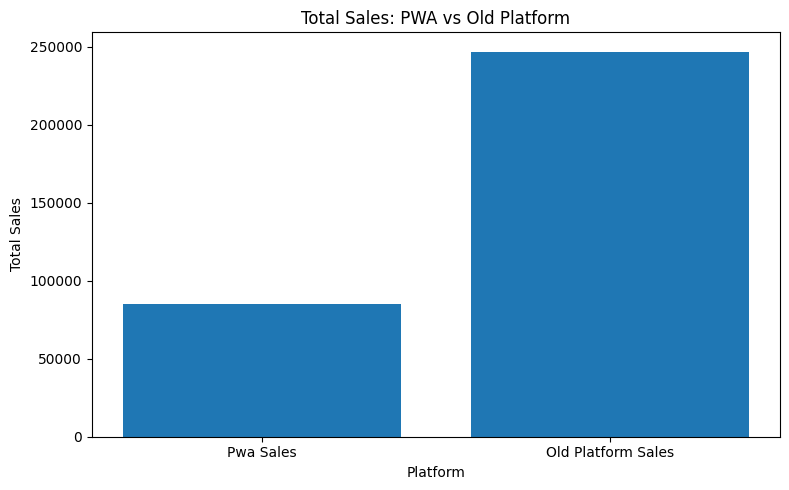

In [30]:
pwa_total = data2['pwa_sales'].sum()
old_total = data2['old_platform_sales'].sum()

platforms = ['Pwa Sales', 'Old Platform Sales']
sales = [pwa_total, old_total]

plt.figure(figsize=(8,5))
bars = plt.bar(platforms, sales)

plt.title('Total Sales: PWA vs Old Platform')
plt.ylabel('Total Sales')
plt.xlabel('Platform')
plt.tight_layout()
plt.show()

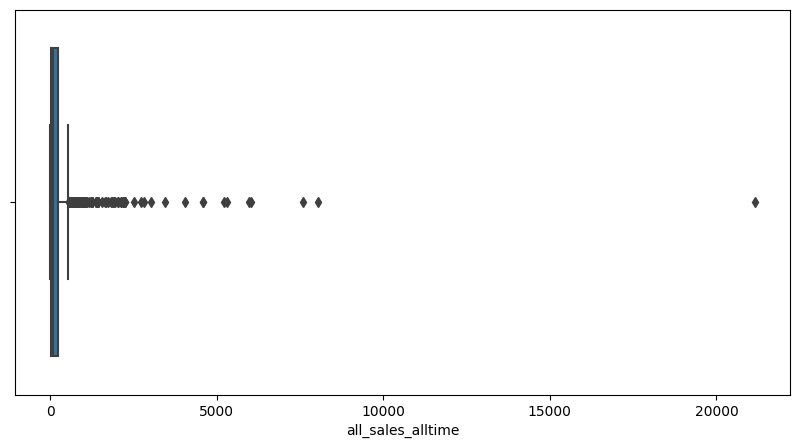

In [31]:
plt.figure(figsize=(10,5))
sns.boxplot(x=data2['all_sales_alltime']);

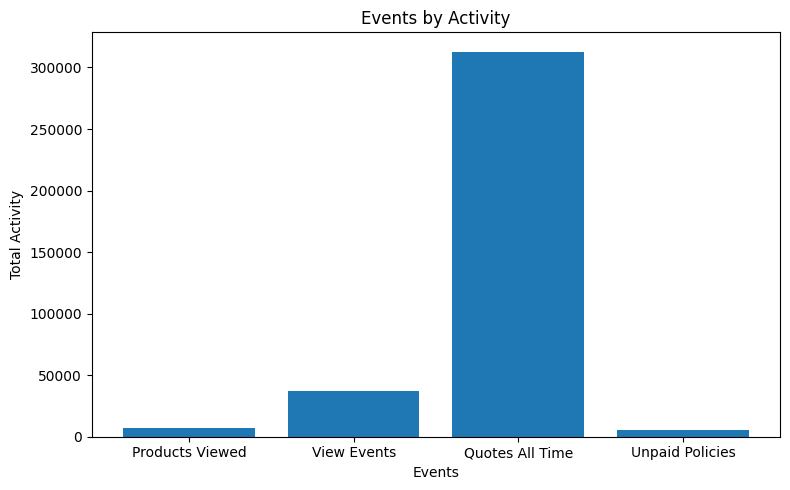

In [32]:
products_viewed_total = data2['products_viewed'].sum()
view_events_total = data2['view_events'].sum()
quotes_alltime_total = data2['quotes_alltime'].sum()
unpaid_total = data2['unpaid_policies'].sum()


events = ['Products Viewed', 'View Events', 'Quotes All Time', 'Unpaid Policies']
activity = [products_viewed_total, view_events_total, quotes_alltime_total, unpaid_total]

plt.figure(figsize=(8,5))
bars = plt.bar(events, activity)

plt.title('Events by Activity')
plt.ylabel('Total Activity')
plt.xlabel('Events')
plt.tight_layout()
plt.show()

In [33]:
latest_date = data2['last_sale_date'].max()   #the most recent date
latest_date

#days since last sale
data2['days_since_last_sale'] = (latest_date - data2['last_sale_date']).dt.days

#categorise agents
data2['sales_recency'] = pd.cut(
    data2['days_since_last_sale'],
    bins = [-1, 30, float('inf')],
    labels = ['Recent (0- 30 days)', 'Inactive (> 30 days)']
)

#missing dates
data2['sales_recency'] = data2['sales_recency'].cat.add_categories('No Sales').fillna('No Sales')

In [34]:
latest_date = data2['last_sale_date'].max()   #the most recent date
latest_date

#days since last sale
data2['days_since_last_sale'] = (latest_date - data2['last_sale_date']).dt.days

#categorise agents
data2['sales_recency'] = pd.cut(
    data2['days_since_last_sale'],
    bins = [-1, 30, float('inf')],
    labels = ['Recent (0- 30 days)', 'Inactive (> 30 days)']
)

#missing dates
data2['sales_recency'] = data2['sales_recency'].cat.add_categories('No Sales').fillna('No Sales')

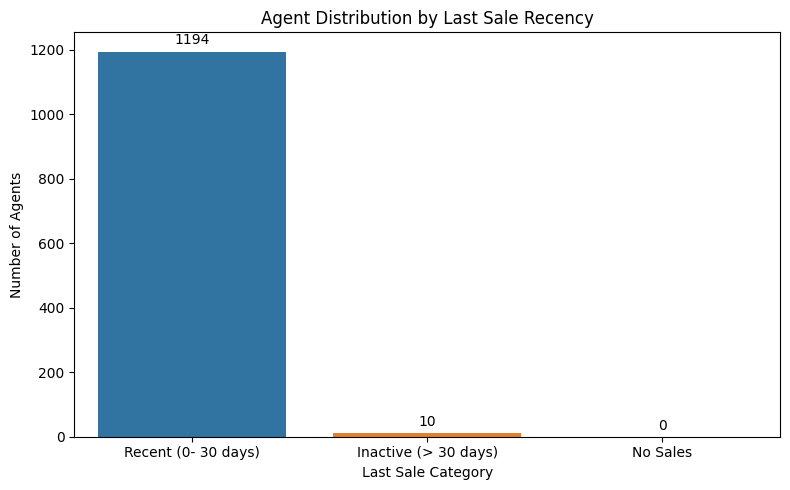

In [35]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=data2,
    x ='sales_recency',
    order = [
        'Recent (0- 30 days)',
        'Inactive (> 30 days)',
        'No Sales'
    ]
)

plt.title('Agent Distribution by Last Sale Recency')
plt.xlabel('Last Sale Category')
plt.ylabel('Number of Agents')

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

#### Combine the two dataframes; the dropper agents and the low frequency buyers


In [48]:
# Known test / internal accounts
TEST_EMAILS = {
    'maksokv@gmail.com',                         # "zarko maksovic test"
    'ivana-agent@mailinator.com',                # "Ivana Agent"
    'caskatnk+intagentlamiexternal@gmail.com',   # internal account, shares a phone with the Zarko test account
}
# Pattern backstop for future extracts
NAME_PAT  = r'\btest\b|\bdemo\b|\bdummy\b'
EMAIL_PAT = r'mailinator|\btest\b|\+int|example\.com'

def remove_test_rows(df, sheet):
    email = df['email'].str.strip().str.lower()
    is_test = (
        email.isin(TEST_EMAILS)
        | df['user_name'].str.contains(NAME_PAT, case=False, regex=True, na=False)
        | email.str.contains(EMAIL_PAT, regex=True, na=False)
    )
    print(f"{sheet}: removing {is_test.sum()} test rows")
    print(df.loc[is_test, ['user_name', 'email', 'phone_number']].to_string(), '\n')
    return df.loc[~is_test].reset_index(drop=True)

drop = remove_test_rows(data, 'Droppers')
low  = remove_test_rows(data2, 'Low-freq')
print(drop.shape, low.shape)

Droppers: removing 3 test rows
              user_name                                    email  phone_number
34  zarko maksovic test                        maksokv@gmail.com  254723496470
36         Mary Kithuku  caskatnk+intagentlamiexternal@gmail.com  254723496470
97          Ivana Agent               ivana-agent@mailinator.com   25476710922 

Low-freq: removing 0 test rows
Empty DataFrame
Columns: [user_name, email, phone_number]
Index: [] 

(364, 14) (1204, 16)


In [49]:
# Columns unique to each dataframe
print("Only in data2:")
print(sorted(set(data2.columns) - set(data.columns)))

print("\nOnly in data:")
print(sorted(set(data.columns) - set(data2.columns)))

print("\nColumns shared by both:")
print(sorted(set(data.columns) & set(data2.columns)))

Only in data2:
['sales_since_sep30', 'viewed_per_sale']

Only in data:
[]

Columns shared by both:
['all_sales_alltime', 'county', 'days_since_last_sale', 'email', 'last_sale_date', 'old_platform_sales', 'phone_number', 'products_viewed', 'pwa_sales', 'quotes_alltime', 'sales_recency', 'unpaid_policies', 'user_name', 'view_events']


In [50]:

# Make copies so the original dataframes remain unchanged
data2_copy = data2.copy()
data_copy = data.copy()

# Create the target label
data2_copy['is_dropper'] = 0
data_copy['is_dropper'] = 1

# Combine both datasets
combined = pd.concat(
    [data2_copy, data_copy],
    ignore_index=True,
    sort=False
)

# Check the result
print(combined.shape)
print(combined['is_dropper'].value_counts())
combined

(1571, 17)
is_dropper
0    1204
1     367
Name: count, dtype: int64


,products_viewed,view_events,sales_since_sep30,viewed_per_sale,all_sales_alltime,quotes_alltime,user_name,county,email,phone_number,unpaid_policies,pwa_sales,old_platform_sales,last_sale_date,days_since_last_sale,sales_recency,is_dropper
0,43,136,2.0,21.5,5,6,Eastman Magembe,NaN,emagembe2019@gmail.com,254705440772,0,3,2,2026-10-30,1.0,Recent (0- 30 days),0
1,35,78,2.0,17.5,20,29,Benson Anunda Simiyu,Nairobi City,anundabenson2002@gmail.com,254112572179,3,19,1,2026-10-19,12.0,Recent (0- 30 days),0
2,17,53,1.0,17.0,218,237,Simon Mwandima,Nairobi City,nadimainsurance@gmail.com,254722518214,2,20,198,2026-10-02,29.0,Recent (0- 30 days),0
3,12,37,1.0,12.0,104,102,James Muoki,Nairobi City,jmuoki88@gmail.com,254714831970,5,76,28,2026-10-15,16.0,Recent (0- 30 days),0
4,11,44,1.0,11.0,2,11,ROSE MULI,Nairobi City,rose@fursainsurance.co.ke,254111667594,0,2,0,2026-10-01,30.0,Recent (0- 30 days),0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1566,1,2,NaN,NaN,3,9,chelsea kinya,Mombasa,chelseakinya@gmail.com,254713019064,1,3,0,2026-09-14,15.0,Recent (0- 30 days),1
1567,1,2,NaN,NaN,0,1,Beatrice Oloo,Mombasa,beatrice.oloo3@gmail.com,254720254514,0,0,0,NaT,NaN,No Sales,1
1568,1,2,NaN,NaN,17,20,Geoffrey Nyakundi Basweti,Nairobi City,baswetigeoffrey@gmail.com,254721584681,2,16,1,2026-08-04,56.0,Inactive (> 30 days),1
1569,1,2,NaN,NaN,7,7,Elizabeth Wahome,Nairobi City,elizabethwangare4@gmail.com,254717959064,0,7,0,2026-07-24,67.0,Inactive (> 30 days),1


In [40]:
combined.columns

Index(['products_viewed', 'view_events', 'sales_since_sep30',
       'viewed_per_sale', 'all_sales_alltime', 'quotes_alltime', 'user_name',
       'county', 'email', 'phone_number', 'unpaid_policies', 'pwa_sales',
       'old_platform_sales', 'last_sale_date', 'days_since_last_sale',
       'sales_recency', 'is_dropper'],
      dtype='object')

In [51]:
# the earliest and most recent date
earliest_date = combined['last_sale_date'].min()
print(f"Earliest date: {earliest_date}")
latest_date = combined['last_sale_date'].max() 
print(f"Latest date: {latest_date}")

Earliest date: 2024-07-09 00:00:00
Latest date: 2026-10-31 00:00:00


Earliest date is July, 9th 2024 and the latest date is 31st October 2026.

We check the interactions of the users with both platforms, but this includes only historical sales upto now since the sales are not dated

### Agent behavior by Platform (PWA and Old Platform) 

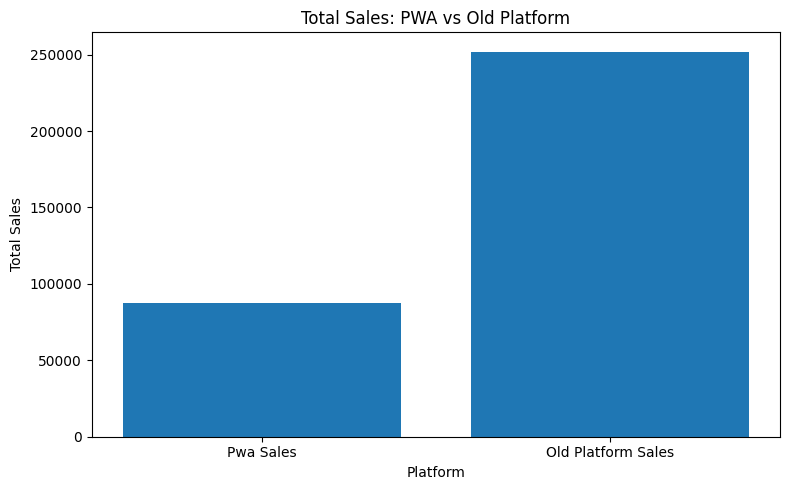

In [53]:
pwa_total = combined['pwa_sales'].sum()
old_total = combined['old_platform_sales'].sum()

platforms = ['Pwa Sales', 'Old Platform Sales']
sales = [pwa_total, old_total]

plt.figure(figsize=(8,5))
bars = plt.bar(platforms, sales)

plt.title('Total Sales: PWA vs Old Platform')
plt.ylabel('Total Sales')
plt.xlabel('Platform')
plt.tight_layout()
plt.show()

In [54]:
sales_comparison = combined.groupby('is_dropper')[['pwa_sales', 'old_platform_sales']].sum().reset_index()

sales_comparison

,is_dropper,pwa_sales,old_platform_sales
0,0,84853,246951
1,1,2451,5009


Low freq buyers old-platform sales are approximately 2.9 times their PWA sales and the droppers, sales are approximately twice their PWA sales. Despite having no sales since September 30 , they have substantial historical sales.

##### *Observations*

1. The old platform dominates historical sales. Both groups have generated more sales through the old platform than through the PWA.

2. Droppers are not necessarily poor-performing agents. Their historical sales indicate that they have previously generated business. Their classification reflects inactivity since September 30, not necessarily low lifetime productivity.

3. Low-frequency buyers have stronger cumulative sales. This is expected to some extent because they are still generating sales, whereas droppers have stopped generating sales within your observation window.

Due to the bias of how many agents belong in each category, 367 dropper agents and 1204 low freq buyers, Let's calculate the average PWA and old-platform sales per agent, separately for droppers and low-frequency buyers.

In [64]:
avg_sales = combined.groupby('is_dropper').agg(
    agents=('user_name', 'nunique'),
    avg_pwa_sales = ('pwa_sales', 'mean'),
    avg_old_platform_sales = ('old_platform_sales', 'mean')
).reset_index()

avg_sales

,is_dropper,agents,avg_pwa_sales,avg_old_platform_sales
0,0,1202,70.475914,205.108804
1,1,366,6.678474,13.648501


In [66]:
avg_sales['agent_category'] = avg_sales['is_dropper'].map({
    0: 'Low-frequency Buyers',
    1: 'Droppers'
})

avg_sales = avg_sales[
    ['agent_category', 'agents', 'avg_pwa_sales', 'avg_old_platform_sales']
].round(2)

avg_sales

,agent_category,agents,avg_pwa_sales,avg_old_platform_sales
0,Low-frequency Buyers,1202,70.48,205.11
1,Droppers,366,6.68,13.65


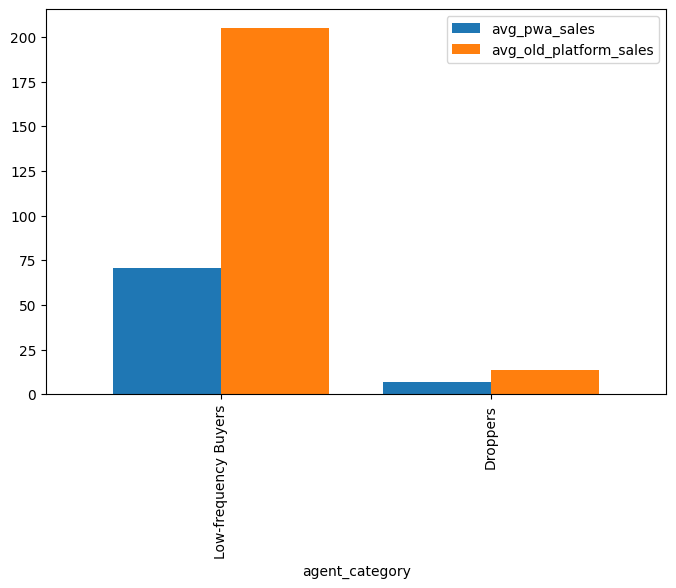

In [67]:
avg_sales.plot(
    x = 'agent_category',
    y = ['avg_pwa_sales', 'avg_old_platform_sales'],
    kind = 'bar',
    figsize=(8,5),
    width=0.8
);

The gap between droppers and low-freq buyers is mostly about size. Lifetime sales lean towards the old platform in both groups, but most droppers are small agents who sold mainly on the PWA, and the old-platform sellers among them are a minority.

### 2. User behavior by activity.

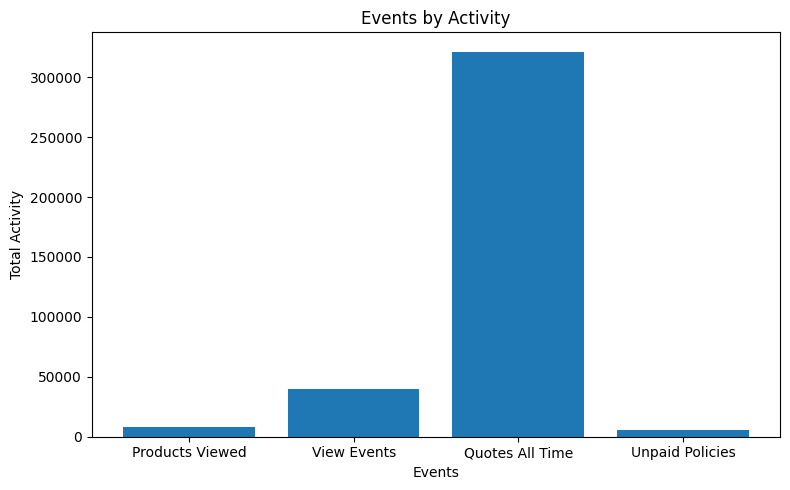

In [58]:
products_viewed_total = combined['products_viewed'].sum()
view_events_total = combined['view_events'].sum()
quotes_alltime_total = combined['quotes_alltime'].sum()
unpaid_total = combined['unpaid_policies'].sum()


events = ['Products Viewed', 'View Events', 'Quotes All Time', 'Unpaid Policies']
activity = [products_viewed_total, view_events_total, quotes_alltime_total, unpaid_total]

plt.figure(figsize=(8,5))
bars = plt.bar(events, activity)

plt.title('Events by Activity')
plt.ylabel('Total Activity')
plt.xlabel('Events')
plt.tight_layout()
plt.show()

In [71]:
activity_comparison = combined.groupby('is_dropper')[
    ['products_viewed','view_events', 'quotes_alltime', 'unpaid_policies']
].sum().reset_index()

activity_comparison

,is_dropper,products_viewed,view_events,quotes_alltime,unpaid_policies
0,0,7285,37237,312927,5726
1,1,843,2311,8420,214


How much they use the app

An agent who is still selling opens about 6 products and keeps going back to them, about 31 visits in total. A dropper opens about 2 products and visits about 6 times in total. They look briefly and then leave.

How big their business is

Still-selling agents have made about 260 quotes each over their time with LAMI. Droppers have made about 23. Both groups turn roughly one quote into one sale. Droppers aren’t worse at closing; they just do much less business overall.

Their share of the activity

Droppers are about 1 in 4 agents.They account for only about 1 in 16 product visits and about 1 in 33 quotes.

Unpaid policies

About 3 in every 100 policies that droppers sold are unpaid, against about 2 in 100 for agents still selling. The gap is small, but it may be worth asking whether payment problems put some agents off.

Two things to keep in mind

Product visits only count since Sep 30, while quotes and unpaid policies cover each agent’s whole history.
The list of still-selling agents only includes people who viewed at least 2 products. Part of the difference in visits comes from how the lists were built.

#### *Bottom line: droppers are mostly small, occasional agents who tried the PWA lightly and didn’t stay. They aren’t big sellers who suddenly disappeared. Helping new and small agents get comfortable with the PWA early may matter more than chasing the large agents.*

### Sales Distribution by County/ Location

<Axes: ylabel='county_clean'>

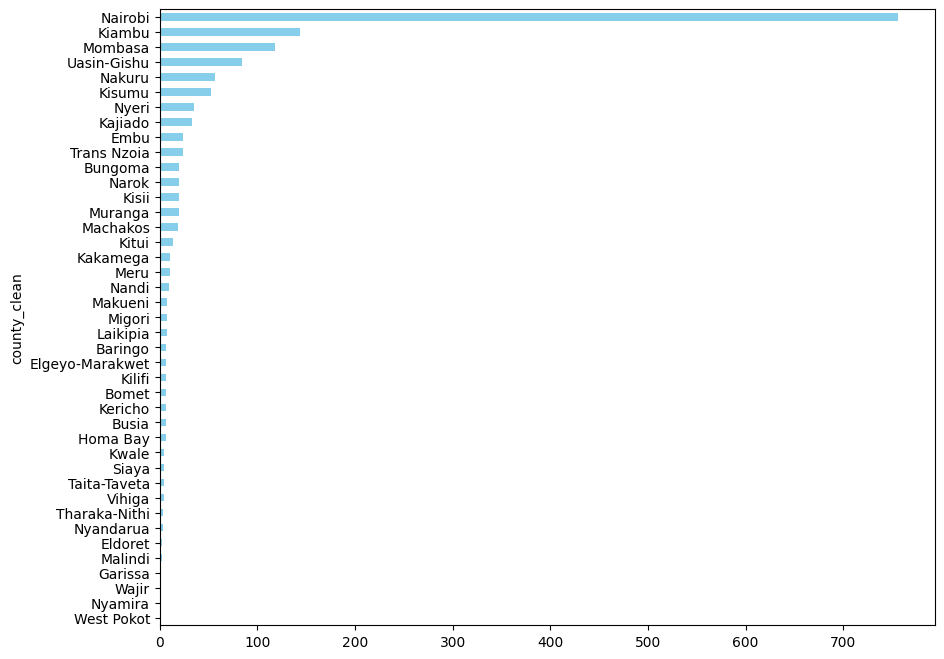

In [62]:


combined['county_clean'] = (
    combined['county']
    .str.strip()
    .str.title()
    .replace({
        'Nairobi City': 'Nairobi',
        'Homabay': 'Homa Bay',
        'Elgeyo / Marakwet': 'Elgeyo-Marakwet',
        'Taita / Taveta': 'Taita-Taveta'
    })
)

county_sales = combined['county_clean'].value_counts().sort_values()
county_sales.plot(kind='barh', figsize=(10, 8), color='skyblue')
